# 01 - Data Cleaning

**Project:** Research Paper Discovery and Trend Analysis (Phase 1)
**Owner:** Person A (data pipeline)

## What this notebook does

It takes the raw filtered arXiv data, checks its quality, cleans it, and saves the final dataset that the whole project uses. Every step has a short explanation of *what* is done and *why*.

| Step | Section |
|---|---|
| 1 | Load the raw data |
| 2 | Missing values |
| 3 | Duplicates |
| 4 | Inconsistent formats (LaTeX, URLs, dates, categories) |
| 5 | Bad records (withdrawn papers, tiny abstracts) |
| 6 | Outliers (abstract and title length) |
| 7 | Summary of all issues found |
| 8 | Run the cleaning pipeline |
| 9 | Before / after examples |
| 10 | The two text versions we create |
| 11 | Validation of the final dataset |
| 12 | Save the cleaned dataset |
| 13 | Conclusions |

## Where the data comes from

- **Source:** the *arXiv Dataset* published by Cornell University on Kaggle (a JSON file with one paper per line: id, title, abstract, categories, version dates, and more).
- **Step A1** (`src/preprocessing.py`) streamed that huge file line by line and kept only papers whose **primary category** is `cs.LG`, `cs.CL` or `cs.CV`, submitted between **2018 and 2024**. To keep the data balanced and manageable, at most **40,000 papers per category** were kept (random sample, seed 42). The result is `papers_raw.parquet`, which is the input of this notebook.
- **Step A2** (`src/cleaning.py`) is the cleaning code. This notebook inspects the problems first, then calls that code and checks the result.

> **Parquet** is a compressed, column-based file format for tables. It is smaller and faster than CSV, remembers data types, and handles messy text (commas, quotes, newlines) safely.

## Setup

The next cells make the notebook work both on **Kaggle** and on a **local machine**. On Kaggle it clones the project repo (to import `src/`) and finds the data in the attached dataset. Locally it expects to run from the `notebooks/` folder of the repo, with the data in `data/`.

In [15]:
import os, sys, subprocess

if os.path.exists("/kaggle/input"):                       # running on Kaggle
    REPO_DIR = "/kaggle/working/research_paper_disc_project"
    # honestly speaking the repository is public and we dont really need 
    # a github secret, but this part would till work with the public repo
    # thats why im not changing it (too lazy lol)
    if not os.path.exists(REPO_DIR):
        url = "https://github.com/MohammadIbraheem71/research_paper_disc_project.git"
        try:                                              # private repo: needs a GITHUB_TOKEN secret
            from kaggle_secrets import UserSecretsClient
            url = url.replace("https://", f"https://{UserSecretsClient().get_secret('GITHUB_TOKEN')}@")
        except Exception:
            pass
        r = subprocess.run(["git", "clone", url, REPO_DIR], capture_output=True)
        assert r.returncode == 0, "git clone failed (private repo? add a GITHUB_TOKEN secret in Kaggle Add-ons > Secrets)"
    else:
        subprocess.run(["git", "-C", REPO_DIR, "pull"], capture_output=True)
else:                                                     # running locally
    REPO_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()

sys.path.insert(0, REPO_DIR)
print("repo folder:", REPO_DIR)

repo folder: /kaggle/working/research_paper_disc_project


In [16]:
# the spaCy English model is needed for lemmatization (step 8)
import spacy
try:
    spacy.load("en_core_web_sm")
except OSError:
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
print("spaCy model ready")

spaCy model ready


In [17]:
import re, io, glob, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import CATEGORIES, YEAR_MIN, YEAR_MAX, MAX_PER_CATEGORY, SEED, SAMPLE_SIZE
from src.cleaning import clean_text, build_papers, MIN_ABSTRACT_WORDS, _URL, _MATH

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# --- paths ---
ON_KAGGLE = os.path.exists("/kaggle/input")
if ON_KAGGLE:
    found = glob.glob("/kaggle/input/**/papers_raw.parquet", recursive=True)
    assert found, "papers_raw.parquet not found: attach the Kaggle dataset that contains it (Add Input)"
    RAW_PATH = found[0]
    OUT_DIR = "/kaggle/working"
    IMAGES_DIR = "/kaggle/working/images"
else:
    RAW_PATH = os.path.join(REPO_DIR, "data", "papers_raw.parquet")
    OUT_DIR = os.path.join(REPO_DIR, "data")
    IMAGES_DIR = os.path.join(REPO_DIR, "images")
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(IMAGES_DIR, exist_ok=True)

print("raw data  :", RAW_PATH)
print("output dir:", OUT_DIR)
print("figures   :", IMAGES_DIR)
print("categories:", CATEGORIES, "| years:", YEAR_MIN, "-", YEAR_MAX, "| cap per category:", MAX_PER_CATEGORY)

raw data  : /kaggle/input/datasets/mohammadibraheem71/arxiv-papers-cleaned/papers_raw.parquet
output dir: /kaggle/working
figures   : /kaggle/working/images
categories: ['cs.LG', 'cs.CL', 'cs.CV'] | years: 2018 - 2024 | cap per category: 40000


## 1. Load the raw data

First look at what we have: size, columns, data types and a few rows. This is the "before" picture for the whole notebook.

In [18]:
raw = pd.read_parquet(RAW_PATH)
print("shape:", raw.shape)
print(f"memory: {raw.memory_usage(deep=True).sum() / 1e6:.0f} MB")
display(raw.dtypes.to_frame("dtype"))
display(raw.head(3))

shape: (120000, 6)
memory: 187 MB


,dtype
id,object
title,object
abstract,object
categories,object
primary_category,object
date,datetime64[ns]


,id,title,abstract,categories,primary_category,date
0,1801.00384,Error-Robust Multi-View Clustering,"In the era of big data, data may come from multiple sources, known as multi-view data. Multi-view clusteri...",cs.LG,cs.LG,2018-01-01 02:42:04
1,1801.00388,Beyond Word Embeddings: Learning Entity and Concept Representations from Large Scale Knowledge Bases,Text representations using neural word embeddings have proven effective in many NLP applications. Recent r...,cs.CL cs.AI cs.IR cs.SI,cs.CL,2018-01-01 03:43:30
2,1801.00409,PronouncUR: An Urdu Pronunciation Lexicon Generator,"State-of-the-art speech recognition systems rely heavily on three basic components: an acoustic model, a p...",cs.CL,cs.CL,2018-01-01 07:54:09


**Columns in the raw data**

| Column | Meaning |
|---|---|
| `id` | arXiv identifier (unique per paper) |
| `title`, `abstract` | the text we analyse (newlines already collapsed by step A1) |
| `categories` | all categories of the paper, as one space-separated string |
| `primary_category` | the first listed category (our label for classification later) |
| `date` | submission date of the **first version** of the paper |

## 2. Missing values

Missing titles, abstracts or dates would break the text processing and the time analysis, so we check two things: real missing values (`NaN` / `NaT`) and **empty strings**, which look present but contain nothing.

In [19]:
text_cols = ["id", "title", "abstract", "categories", "primary_category"]
empty = pd.Series({c: int((raw[c].str.strip() == "").sum()) for c in text_cols}, name="empty string")
missing = pd.concat([raw.isna().sum().rename("NaN / NaT"), empty], axis=1).fillna(0).astype(int)
display(missing)

mask_missing = raw.isna().any(axis=1) | raw[text_cols].apply(lambda s: s.str.strip() == "").any(axis=1)
n_missing_rows = int(mask_missing.sum())
print("rows with any missing / empty value:", n_missing_rows)

,NaN / NaT,empty string
id,0,0
title,0,0
abstract,0,0
categories,0,0
primary_category,0,0
date,0,0


rows with any missing / empty value: 0


**Handling:** rows with a missing id, title, abstract, date or category are dropped, because every downstream step needs all of them and imputing text would invent data. (The step-8 pipeline uses `dropna` on these columns, and empty abstracts are removed by the minimum-length rule in section 5.)

## 3. Duplicates

Three kinds of duplicates matter:

- **Duplicate ids:** the same paper twice.
- **Near-identical titles:** the same paper under a different id, or reposted. Titles are compared after removing LaTeX, case and punctuation, so "Deep  Learning!" and "deep learning" count as equal.
- **Identical abstracts:** reported for information. Different papers can share an abstract by accident, so this is only a warning sign, not a reason to drop.

In [20]:
dup_id = int(raw["id"].duplicated().sum())

norm_title = raw["title"].map(clean_text).map(lambda t: re.sub(r"[^a-z0-9]", "", t.lower()))
dup_title_mask = norm_title.duplicated(keep="first")
dup_title = int(dup_title_mask.sum())

dup_abstract = int(raw["abstract"].duplicated().sum())

print("duplicate ids               :", dup_id)
print("near-identical titles       :", dup_title)
print("identical abstracts (info)  :", dup_abstract)

if dup_title:
    groups = raw[norm_title.duplicated(keep=False)].assign(_t=norm_title).sort_values(["_t", "id"])
    print("\nexamples of near-identical titles:")
    display(groups[["id", "title", "primary_category", "date"]].head(8))

duplicate ids               : 0
near-identical titles       : 29
identical abstracts (info)  : 8

examples of near-identical titles:


,id,title,primary_category,date
16069,1911.00234,Active$^2$ Learning: Actively reducing redundancies in Active Learning methods for Sequence Tagging and Ma...,cs.LG,2019-11-01 07:31:02
34232,2103.06490,Active$^2$ Learning: Actively reducing redundancies in Active Learning methods for Sequence Tagging and Ma...,cs.CL,2021-03-11 06:27:31
73913,2305.14450,An Empirical Study on Information Extraction using Large Language Models,cs.CL,2023-05-23 18:17:43
109153,2409.00369,An Empirical Study on Information Extraction using Large Language Models,cs.CL,2024-08-31 07:10:16
34312,2103.07364,A Unified Game-Theoretic Interpretation of Adversarial Robustness,cs.LG,2021-03-12 15:56:28
45862,2111.03536,A Unified Game-Theoretic Interpretation of Adversarial Robustness,cs.LG,2021-11-05 14:57:49
58259,2208.00561,AvatarGen: a 3D Generative Model for Animatable Human Avatars,cs.CV,2022-08-01 01:27:02
64326,2211.14589,AvatarGen: A 3D Generative Model for Animatable Human Avatars,cs.CV,2022-11-26 15:15:45


**Handling:** keep the first occurrence of each id and of each normalised title; drop the rest.

## 4. Inconsistent formats

arXiv abstracts are written by the authors, so the text is full of things that are meaningless (or harmful) for NLP: **LaTeX formulas** (`$\alpha$`), **LaTeX commands** (`\textbf{...}`), **URLs** and stray symbols. We also check that the dates and categories are in the format the rest of the project expects.

In [21]:
has_math = raw["abstract"].map(lambda s: bool(_MATH.search(s)))
has_url = raw["abstract"].map(lambda s: bool(_URL.search(s)))
has_cmd = raw["abstract"].str.contains(r"\\[a-zA-Z]+", regex=True)

fmt = pd.DataFrame({
    "abstracts with $math$": [int(has_math.sum())],
    "abstracts with URLs": [int(has_url.sum())],
    "abstracts with \\commands": [int(has_cmd.sum())],
    "titles with $math$": [int(raw["title"].map(lambda s: bool(_MATH.search(s))).sum())],
}).T.rename(columns={0: "rows"})
display(fmt)

# whitespace problems (step A1 already collapsed newlines, so these should be ~0)
print("titles/abstracts with double spaces or newlines:",
      int(raw["title"].str.contains(r"\s{2,}|\n", regex=True).sum()),
      "/", int(raw["abstract"].str.contains(r"\s{2,}|\n", regex=True).sum()))

,rows
abstracts with $math$,8289
abstracts with URLs,16998
abstracts with \commands,10562
titles with $math$,545


titles/abstracts with double spaces or newlines: 0 / 0


In [22]:
# date and category format checks
print("date dtype:", raw["date"].dtype, "| range:", raw["date"].min(), "->", raw["date"].max())
print("years outside", YEAR_MIN, "-", YEAR_MAX, ":", int((~raw["date"].dt.year.between(YEAR_MIN, YEAR_MAX)).sum()))
print("primary_category not in agreed list:", int((~raw["primary_category"].isin(CATEGORIES)).sum()))
print("primary_category != first of categories:",
      int((raw["categories"].str.split().str[0] != raw["primary_category"]).sum()))
print("\ncategory counts:")
display(raw["primary_category"].value_counts().to_frame("papers"))

date dtype: datetime64[ns] | range: 2018-01-01 02:42:04 -> 2024-12-31 22:56:19
years outside 2018 - 2024 : 0
primary_category not in agreed list: 0
primary_category != first of categories: 0

category counts:


,papers
primary_category,
cs.LG,40000
cs.CL,40000
cs.CV,40000


A few concrete examples of what the text cleaning does (sentences that contain LaTeX or a URL, before and after):

In [23]:
def sentence_with_match(text):
    for s in re.split(r"(?<=[.!?])\s+", text):
        if _MATH.search(s) or _URL.search(s):
            return s
    return None

shown, seen = 0, set()
for abstract in raw.loc[has_math | has_url, "abstract"].head(500):
    s = sentence_with_match(abstract)
    if s and 40 < len(s) < 300 and s not in seen:
        seen.add(s)
        print("BEFORE:", s)
        print("AFTER :", clean_text(s), "\n")
        shown += 1
    if shown == 3:
        break

BEFORE: Our results state that expectation of $L_2$-norm of adversarial perturbations is $O\left(\frac{1}{\sqrt{n}}\right)$ and therefore shrinks to 0 as image resolution $n$ becomes arbitrarily large.
AFTER : Our results state that expectation of -norm of adversarial perturbations is and therefore shrinks to 0 as image resolution becomes arbitrarily large. 

BEFORE: Our VnCoreNLP is open-source and available at: https://github.com/vncorenlp/VnCoreNLP
AFTER : Our VnCoreNLP is open-source and available at: 

BEFORE: The vector representations of words, bigrams, trigrams, abbreviations, and PubMed title+abstracts are all publicly available from http://arrowsmith.psych.uic.edu for release under CC-BY-NC license.
AFTER : The vector representations of words, bigrams, trigrams, abbreviations, and PubMed title+abstracts are all publicly available from for release under CC-BY-NC license. 



**Handling:** formulas, commands, URLs and stray symbols are removed and whitespace is collapsed. Capital letters and punctuation are **kept** in the light version of the text (`text_raw`), because sentence embeddings and the language model work better on natural-looking text.

## 5. Bad records

Some records are valid rows but useless papers:

- **Withdrawn papers:** the abstract is just a notice such as "This paper has been withdrawn". We flag abstracts that mention *withdrawn* **and** are short (80 words or fewer), so a real paper that merely mentions the word is kept.
- **Tiny abstracts:** fewer than 30 words after cleaning. These carry too little text for topic modeling or classification.

In [24]:
abstract_clean = raw["abstract"].map(clean_text)
abs_words_raw = raw["abstract"].str.split().str.len()

withdrawn = raw["abstract"].str.contains(r"\bwithdrawn\b", case=False, regex=True) & (abs_words_raw <= 80)
short = abstract_clean.str.split().str.len() < MIN_ABSTRACT_WORDS

print("withdrawn notices:", int(withdrawn.sum()))
print(f"abstracts under {MIN_ABSTRACT_WORDS} words:", int(short.sum()))

bad = raw[withdrawn | short].assign(words=abstract_clean.str.split().str.len())
if len(bad):
    display(bad[["id", "title", "abstract", "words"]].head(6))

withdrawn notices: 1
abstracts under 30 words: 52


,id,title,abstract,words
3867,1807.11643,Brain MRI Image Super Resolution using Phase Stretch Transform and Transfer Learning,A hallucination-free and computationally efficient algorithm for enhancing the resolution of brain MRI ima...,16
4986,1809.07904,Automatic Rule Learning for Autonomous Driving Using Semantic Memory,This paper presents a novel approach for automatic rule learning applicable to an autonomous driving syste...,20
6382,1811.07691,Improving speech emotion recognition via Transformer-based Predictive Coding through transfer learning,"I have submitted a new version to arXiv:1910.13806. I forget to choose to replace the old version, but sub...",25
8582,1903.00117,A Sketch Based 3D Shape Retrieval Approach Based on Efficient Deep Point-to-Subspace Metric Learning,A sketch based 3D shape retrieval,6
8933,1903.07303,M$^2$VAE - Derivation of a Multi-Modal Variational Autoencoder Objective from the Marginal Joint Log-Likel...,This work gives an in-depth derivation of the trainable evidence lower bound obtained from the marginal jo...,29
10544,1905.05407,On the number of k-skip-n-grams,The paper proves that the number of k-skip-n-grams for a corpus of size $L$ is $$\frac{Ln + n + k' - n^2 -...,16


**Handling:** both groups are dropped.

## 6. Outliers

For text data the natural numeric features are the **length of the title and the abstract** (in words). Extreme lengths can hurt later steps: very long abstracts get truncated by the embedding model (it reads about 256 tokens), and very short ones carry little signal.

We look at the distribution, count outliers with the standard **IQR rule** (below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR), and then decide what to do with them.

In [25]:
lengths = pd.DataFrame({
    "abstract_words": abstract_clean.str.split().str.len(),
    "title_words": raw["title"].map(clean_text).str.split().str.len(),
})
display(lengths.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1))

def iqr_fences(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in lengths:
    lo, hi = iqr_fences(lengths[col])
    rows.append({"feature": col, "lower fence": round(lo, 1), "upper fence": round(hi, 1),
                 "below": int((lengths[col] < lo).sum()), "above": int((lengths[col] > hi).sum())})
outlier_table = pd.DataFrame(rows).set_index("feature")
display(outlier_table)

,abstract_words,title_words
count,120000.0,120000.0
mean,169.6,9.4
std,45.3,3.1
min,5.0,1.0
1%,70.0,3.0
5%,98.0,5.0
25%,139.0,7.0
50%,168.0,9.0
75%,199.0,11.0
95%,249.0,15.0


,lower fence,upper fence,below,above
feature,,,,
abstract_words,49.0,289.0,253,290
title_words,1.0,17.0,0,1545


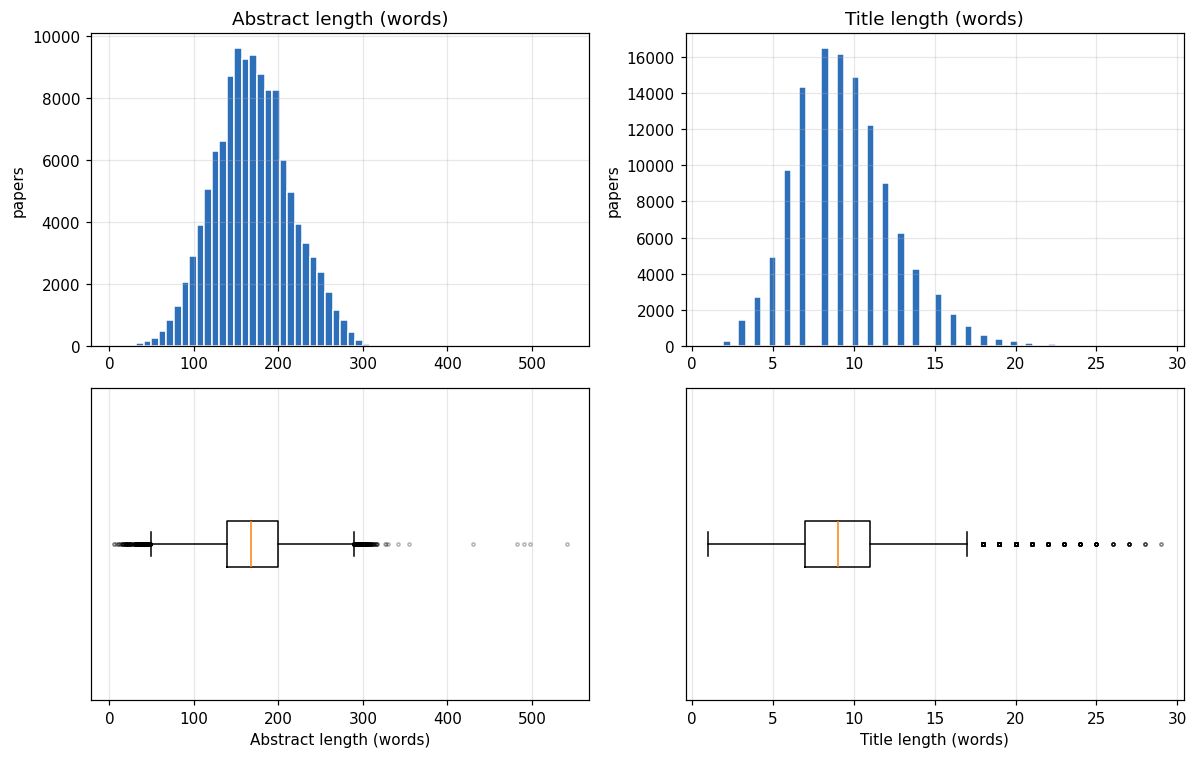

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, (col, label) in enumerate([("abstract_words", "Abstract length (words)"), ("title_words", "Title length (words)")]):
    axes[0, j].hist(lengths[col], bins=60, color="#2E6FBA", edgecolor="white")
    axes[0, j].set_title(label); axes[0, j].set_ylabel("papers")
    axes[1, j].boxplot(lengths[col], vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
    axes[1, j].set_xlabel(label); axes[1, j].set_yticks([])
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "01_length_outliers.png"), dpi=150)
plt.show()

In [27]:
print("longest abstracts:")
display(raw.loc[lengths["abstract_words"].nlargest(3).index, ["id", "title"]].assign(
    words=lengths["abstract_words"].nlargest(3).values))
print("shortest abstracts (that are still >= 30 words):")
ok = lengths[lengths["abstract_words"] >= MIN_ABSTRACT_WORDS]["abstract_words"]
display(raw.loc[ok.nsmallest(3).index, ["id", "title"]].assign(words=ok.nsmallest(3).values))

longest abstracts:


,id,title,words
116427,2411.13631,Sparse Input View Synthesis: 3D Representations and Reliable Priors,541
37694,2105.12210,The Nonlinearity Coefficient - A Practical Guide to Neural Architecture Design,498
7150,1812.07207,Multiple topic identification in human/human conversations,491


shortest abstracts (that are still >= 30 words):


,id,title,words
86699,2311.13784,DaG LLM ver 1.0: Pioneering Instruction-Tuned Language Modeling for Korean NLP,30
108738,2408.14332,One-layer transformers fail to solve the induction heads task,30
5912,1811.00693,Meta-path Augmented Response Generation,31


### Decision on outliers: keep them (document, do not delete)

- The very short abstracts are already removed by the **minimum-length rule** (section 5), so what is left at the low end is real, if brief, papers.
- The very long abstracts and titles are legitimate papers. The embedding model simply truncates the extra text, and the key content of an abstract comes first, so this loses little.
- Removing more rows now would also change the row order and count that the **embeddings, topics and classifier all depend on**, forcing the whole team to redo work for almost no gain.
- TF-IDF, LDA and sentence embeddings are not very sensitive to a few long documents, unlike a linear model fitted directly on raw numeric features.

So the outliers are **kept**, and they are shown above so the choice is visible. (If a later model turns out to be sensitive to length, we can cap the length at the 99th percentile inside that model rather than in the shared dataset.)

## 7. Summary of all issues found

One table with every issue and the action taken. Counts can overlap (one paper can be both a duplicate and have LaTeX), so they do not add up to the number of removed rows; the exact removal is shown in step 8.

,issue,rows affected,action
0,Missing / empty values,0,drop rows
1,Duplicate ids,0,keep first
2,Near-identical titles,29,keep first
3,Withdrawn-paper notices,1,drop rows
4,Abstracts under 30 words,52,drop rows
5,Abstracts with LaTeX math,8289,strip LaTeX
6,Abstracts with URLs,16998,strip URLs
7,"Length outliers (IQR rule, abstract)",543,keep (documented)


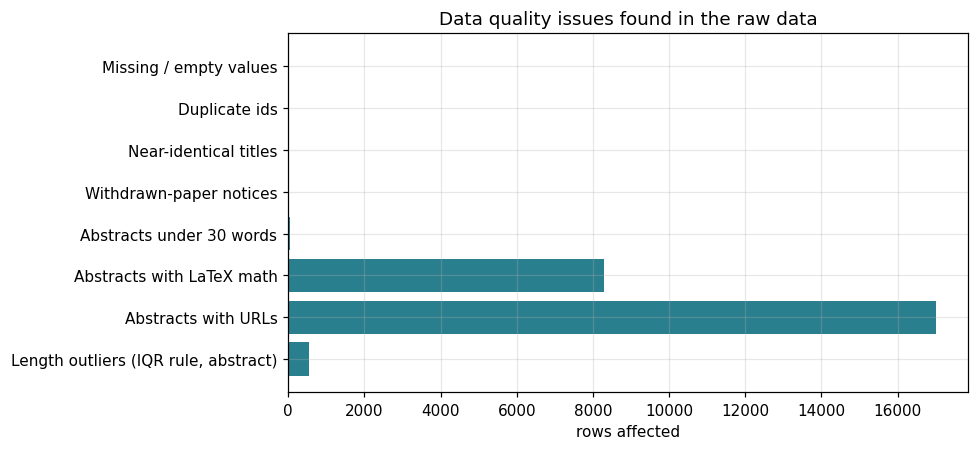

In [28]:
issues = pd.DataFrame([
    ("Missing / empty values", n_missing_rows, "drop rows"),
    ("Duplicate ids", dup_id, "keep first"),
    ("Near-identical titles", dup_title, "keep first"),
    ("Withdrawn-paper notices", int(withdrawn.sum()), "drop rows"),
    (f"Abstracts under {MIN_ABSTRACT_WORDS} words", int(short.sum()), "drop rows"),
    ("Abstracts with LaTeX math", int(has_math.sum()), "strip LaTeX"),
    ("Abstracts with URLs", int(has_url.sum()), "strip URLs"),
    ("Length outliers (IQR rule, abstract)", int(outlier_table.loc["abstract_words", ["below", "above"]].sum()), "keep (documented)"),
], columns=["issue", "rows affected", "action"])
display(issues)

fig, ax = plt.subplots(figsize=(9, 4.2))
plot_df = issues.iloc[::-1]
ax.barh(plot_df["issue"], plot_df["rows affected"], color="#2A7F8E")
ax.set_xlabel("rows affected"); ax.set_title("Data quality issues found in the raw data")
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "01_issues_summary.png"), dpi=150)
plt.show()

## 8. Run the cleaning pipeline

All of the above is applied by one function, `build_papers()` from `src/cleaning.py`. In order, it:

1. drops missing values, duplicate ids, near-identical titles and withdrawn notices;
2. cleans the title and abstract and builds **`text_raw`** (title + abstract, lightly cleaned);
3. drops abstracts under 30 words;
4. extracts `year`, `month` and `quarter` from the date;
5. builds **`text_lemma`** (heavily cleaned and lemmatized) with spaCy;
6. sorts by `id` **once** and checks that there are no nulls and that ids are unique.

The lemmatization step takes a few minutes on ~120k papers.

In [29]:
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    papers = build_papers(raw)
print(buf.getvalue())

summary = pd.DataFrame({"rows": [len(raw), len(papers), len(raw) - len(papers)]},
                       index=["before cleaning", "after cleaning", "removed"])
summary["share of raw"] = (summary["rows"] / len(raw) * 100).round(2).astype(str) + " %"
display(summary)

after dropping missing/duplicates/withdrawn: 119970 (from 120000)
after dropping abstracts under 30 words: 119919
lemmatizing (a few minutes for ~100k papers)...



,rows,share of raw
before cleaning,120000,100.0 %
after cleaning,119919,99.93 %
removed,81,0.07 %


## 9. Before / after

Rows removed per step, and one full example of a paper before and after cleaning.

In [30]:
removed_df = pd.DataFrame({
    "step": ["missing / duplicates / withdrawn", f"abstract under {MIN_ABSTRACT_WORDS} words", "other (no content words after lemmatizing)"],
})
log = buf.getvalue()
m1 = re.search(r"after dropping missing/duplicates/withdrawn: (\d+) \(from (\d+)\)", log)
m2 = re.search(r"abstracts under \d+ words: (\d+)", log)
n0 = len(raw)
n1 = int(m1.group(1)) if m1 else n0
n2 = int(m2.group(1)) if m2 else n1
removed_df["rows removed"] = [n0 - n1, n1 - n2, n2 - len(papers)]
display(removed_df)

,step,rows removed
0,missing / duplicates / withdrawn,30
1,abstract under 30 words,51
2,other (no content words after lemmatizing),0


In [31]:
cmp = raw.merge(papers[["id", "text_raw", "text_lemma"]], on="id")
ex = cmp[cmp["abstract"].map(lambda s: bool(_MATH.search(s)))].head(1)
if ex.empty:
    ex = cmp.head(1)
r = ex.iloc[0]
print("ID   :", r["id"])
print("\nRAW abstract (first 450 chars):\n", r["abstract"][:450])
print("\ntext_raw (first 450 chars):\n", r["text_raw"][:450])
print("\ntext_lemma (first 450 chars):\n", r["text_lemma"][:450])

ID   : 1801.00634

RAW abstract (first 450 chars):
 In this paper, we analyze deep learning from a mathematical point of view and derive several novel results. The results are based on intriguing mathematical properties of high dimensional spaces. We first look at perturbation based adversarial examples and show how they can be understood using topological and geometrical arguments in high dimensions. We point out mistake in an argument presented in prior published literature, and we present a mor

text_raw (first 450 chars):
 High Dimensional Spaces, Deep Learning and Adversarial Examples. In this paper, we analyze deep learning from a mathematical point of view and derive several novel results. The results are based on intriguing mathematical properties of high dimensional spaces. We first look at perturbation based adversarial examples and show how they can be understood using topological and geometrical arguments in high dimensions. We point out mistake in an argum

text_lemma (fir

## 10. The two text versions

Different methods need different input, so we keep two versions of every paper:

| Version | Cleaning | Used for |
|---|---|---|
| `text_raw` | title + abstract, LaTeX/URLs/symbols removed; **case and punctuation kept** | sentence embeddings, BERTopic, retrieval (RAG), the language model |
| `text_lemma` | lowercased, letters only, **stop words removed, lemmatized**, generic academic words removed ("paper", "propose", "approach", ...) | TF-IDF, LDA, classification baselines |

*Lemmatization* reduces a word to its base form ("networks" to "network", "trained" to "train"), so variants of the same word are counted together. Generic academic words appear in almost every abstract and carry no topic information, so removing them helps topic modeling.

This is also the **normalization** of the text. Numeric scaling of the features (TF-IDF weighting, L2 normalization of vectors, train/test split) is done in notebook `03_preprocessing.ipynb`.

In [32]:
words_raw = papers["text_raw"].str.split().str.len()
words_lemma = papers["text_lemma"].str.split().str.len()
vocab_raw = len({w for t in papers["text_raw"] for w in t.lower().split()})
vocab_lemma = len({w for t in papers["text_lemma"] for w in t.split()})

stats = pd.DataFrame({
    "avg words per paper": [words_raw.mean().round(1), words_lemma.mean().round(1)],
    "median words": [words_raw.median(), words_lemma.median()],
    "distinct words (vocabulary)": [vocab_raw, vocab_lemma],
}, index=["text_raw", "text_lemma"])
display(stats)

,avg words per paper,median words,distinct words (vocabulary)
text_raw,179.1,177.0,436150
text_lemma,101.3,100.0,103061


## 11. Validation of the final dataset

Checks that the cleaned data meets the contract the rest of the team relies on.

In [33]:
expected_cols = ["id", "title", "abstract", "text_raw", "text_lemma", "primary_category",
                 "categories", "date", "year", "month", "quarter"]
assert list(papers.columns) == expected_cols, "unexpected columns"
assert papers.isna().sum().sum() == 0, "nulls found"
assert papers["id"].is_unique, "duplicate ids"
assert papers["id"].is_monotonic_increasing, "rows must stay sorted by id"
assert papers["year"].between(YEAR_MIN, YEAR_MAX).all(), "year out of range"
assert papers["quarter"].str.fullmatch(r"\d{4}Q[1-4]").all(), "bad quarter format"
assert papers["primary_category"].isin(CATEGORIES).all(), "unexpected category"
assert (papers["text_raw"].str.len() > 0).all() and (papers["text_lemma"].str.len() > 0).all()
print("all checks passed")

display(papers.dtypes.to_frame("dtype"))
display(papers["primary_category"].value_counts().to_frame("papers"))
display(papers.head(3))

all checks passed


,dtype
id,object
title,object
abstract,object
text_raw,object
text_lemma,object
primary_category,object
categories,object
date,datetime64[ns]
year,int64
month,int64


,papers
primary_category,
cs.CL,39980
cs.CV,39973
cs.LG,39966


,id,title,abstract,text_raw,text_lemma,primary_category,categories,date,year,month,quarter
0,1801.00384,Error-Robust Multi-View Clustering,"In the era of big data, data may come from multiple sources, known as multi-view data. Multi-view clusteri...","Error-Robust Multi-View Clustering. In the era of big data, data may come from multiple sources, known as ...",error robust multi view clustering era big datum datum come multiple source know multi view datum multi vi...,cs.LG,cs.LG,2018-01-01 02:42:04,2018,1,2018Q1
1,1801.00388,Beyond Word Embeddings: Learning Entity and Concept Representations from Large Scale Knowledge Bases,Text representations using neural word embeddings have proven effective in many NLP applications. Recent r...,Beyond Word Embeddings: Learning Entity and Concept Representations from Large Scale Knowledge Bases. Text...,word embedding learning entity concept representations large scale knowledge bases text representation neu...,cs.CL,cs.CL cs.AI cs.IR cs.SI,2018-01-01 03:43:30,2018,1,2018Q1
2,1801.00409,PronouncUR: An Urdu Pronunciation Lexicon Generator,"State-of-the-art speech recognition systems rely heavily on three basic components: an acoustic model, a p...",PronouncUR: An Urdu Pronunciation Lexicon Generator. State-of-the-art speech recognition systems rely heav...,pronouncur urdu pronunciation lexicon generator speech recognition system rely heavily basic component aco...,cs.CL,cs.CL,2018-01-01 07:54:09,2018,1,2018Q1


## 12. Save the cleaned dataset

- `papers.parquet`: the full cleaned dataset used by the whole project.
- `papers_sample.parquet`: a 10,000-paper random sample (seed 42) for fast development and testing.

> **Important:** the row order is fixed (sorted by `id`). The sentence embeddings are matched to this exact order, so the file must never be re-sorted. The data files are **not** committed to GitHub (too large); they are shared through a Kaggle Dataset, linked in the README.

In [34]:
papers.to_parquet(os.path.join(OUT_DIR, "papers.parquet"), index=False)
sample = (papers.sample(min(SAMPLE_SIZE, len(papers)), random_state=SEED)
                .sort_values("id").reset_index(drop=True))
sample.to_parquet(os.path.join(OUT_DIR, "papers_sample.parquet"), index=False)
print("saved", len(papers), "papers and a sample of", len(sample), "to", OUT_DIR)

saved 119919 papers and a sample of 10000 to /kaggle/working


In [35]:
# reproducibility check: does this run give the same rows as the dataset we already shared with the team?
shared = glob.glob("/kaggle/input/**/papers.parquet", recursive=True) if ON_KAGGLE else []
if shared:
    shared_ids = pd.read_parquet(shared[0], columns=["id"])["id"]
    print("same ids in the same order as the shared dataset:", papers["id"].reset_index(drop=True).equals(shared_ids))
else:
    print("no shared papers.parquet attached, skipping this check")

same ids in the same order as the shared dataset: True


## 13. Conclusions

**What we found**

- The raw data was already in good shape: the A1 filter produced a clean table with no structural problems (no unexpected categories, no dates outside 2018-2024, one row per paper).
- The main quality problems were in the **text**: LaTeX formulas and commands, URLs, and stray symbols inside titles and abstracts, plus a handful of withdrawn-paper notices, near-duplicate titles and very short abstracts. In our run, cleaning removed only about **81 of 120,000 rows (0.07 %)** (see the table in section 8 for this run's exact numbers).
- Abstract lengths are right-skewed: most abstracts have a similar, moderate length, with a long tail of very long ones (see the histogram and boxplot in section 6). These outliers are legitimate papers and are **kept**.
- The categories are balanced (about 40,000 papers each) **because we capped them**. The original, uncapped counts were uneven (see the EDA notebook), so the balanced mix does not reflect real arXiv proportions. Topic shares computed later describe this balanced sample, not all of arXiv. This is a limitation to state in the report.

**What this means for modeling**

- Two text versions are available: `text_raw` for embedding-based methods and `text_lemma` for bag-of-words methods.
- Because the dataset is balanced by design, accuracy is a reasonable metric for the classifier, but we will still report macro F1.
- The `quarter` column (e.g. `2021Q3`) is ready for the topic-trend analysis.

**Output of this notebook:** `papers.parquet` (full) and `papers_sample.parquet` (10k), plus the figures in `images/`.